## Setup

In [2]:
!pip install -q mediapipe tqdm

In [3]:
import os, json, time, shutil, zipfile, warnings, threading, urllib.request, requests
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd, cv2, joblib
import matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score, precision_recall_fscore_support
from tqdm.auto import tqdm
warnings.filterwarnings('ignore'); sns.set_theme(style='whitegrid')
SEED = 42; keras.utils.set_random_seed(SEED)
keras.mixed_precision.set_global_policy('mixed_float16')
print('TensorFlow', tf.__version__, '| GPUs:', tf.config.list_physical_devices('GPU'))

from google.colab import drive
drive.mount('/content/drive')
DRIVE_DIR = '/content/drive/MyDrive/SignSense_data'
WORK, PROC, OUT, MODELS = '/content/work', '/content/processed', '/content/results', '/content/results/models'
DATA_DIR = '/content/data'; ROOT = os.path.join(DATA_DIR, 'Pakistan Sign Language Urdu Alphabets')
for d in (WORK, OUT, MODELS, f'{DRIVE_DIR}/results', f'{DRIVE_DIR}/models'): os.makedirs(d, exist_ok=True)
for f in ['processed_metadata.csv', 'label_map.json', 'class_weights.json', 'results/static_test_predictions.npz']: shutil.copy(f'{DRIVE_DIR}/{f}', WORK)

meta = pd.read_csv(f'{WORK}/processed_metadata.csv'); imgs = meta[meta['media_type'] == 'image'].reset_index(drop=True); imgs['is_generated'] = imgs['is_generated'].astype(bool)
STATIC = json.load(open(f'{WORK}/label_map.json'))['static_classes']; K = len(STATIC)
CW = {int(k): v for k, v in json.load(open(f'{WORK}/class_weights.json'))['static'].items()}
y_all = imgs['class_id'].values.astype('int32'); split = imgs['split'].values
tr_m, va_m, te_m = split == 'train', split == 'val', split == 'test'
orig_m = ~imgs['is_generated'].values; subj = imgs['subject'].values
SP = np.load(f'{WORK}/static_test_predictions.npz', allow_pickle=True); assert (SP['y'] == y_all[te_m]).all()
print('train / val / test images:', tr_m.sum(), va_m.sum(), te_m.sum(), '| classes:', K)

TensorFlow 2.21.0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Mounted at /content/drive
train / val / test images: 15062 3060 3238 | classes: 36


## 1. Hand landmarks for every image
Landmarks are extracted from the **raw** images (resized to a maximum side of 480, exactly like the app and Phase 1) and normalized the same way (wrist = origin, scaled by the largest wrist distance). The hand bounding box is stored too, for a possible hand-crop CNN later.

In [4]:
# Raw dataset (needed only for the first extraction)
LM_CACHE = f'{DRIVE_DIR}/results/image_landmarks_raw.npz'
if not os.path.exists(LM_CACHE) and not os.path.isdir(ROOT):
    ZIP = '/content/ualpha40.zip'
    if not os.path.exists(ZIP):
        with requests.get('https://data.mendeley.com/public-api/zip/3pvnnckxyb/download/1', stream=True) as r:
            r.raise_for_status()
            with open(ZIP, 'wb') as f:
                for ch in r.iter_content(chunk_size=1 << 20): f.write(ch)
    with zipfile.ZipFile(ZIP) as z: z.extractall(DATA_DIR)
print('raw dataset needed:', not os.path.exists(LM_CACHE))

raw dataset needed: True


In [5]:
import mediapipe as mp
from mediapipe.tasks import python as mp_python
from mediapipe.tasks.python import vision
MP_MODEL = '/content/hand_landmarker.task'
if not os.path.exists(MP_MODEL):
    urllib.request.urlretrieve('https://storage.googleapis.com/mediapipe-models/hand_landmarker/hand_landmarker/float16/1/hand_landmarker.task', MP_MODEL)
_tl = threading.local()
def landmarker():
    if not hasattr(_tl, 'lm'):                                  # One MediaPipe object per thread
        _tl.lm = vision.HandLandmarker.create_from_options(vision.HandLandmarkerOptions(
            base_options=mp_python.BaseOptions(model_asset_path=MP_MODEL), running_mode=vision.RunningMode.IMAGE, num_hands=1, min_hand_detection_confidence=0.5))
    return _tl.lm

def extract_one(rel):
    bgr = cv2.imread(os.path.join(ROOT, rel))
    if bgr is None: return None
    s = 480 / max(bgr.shape[:2])
    if s < 1: bgr = cv2.resize(bgr, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
    h, w = bgr.shape[:2]
    res = landmarker().detect(mp.Image(image_format=mp.ImageFormat.SRGB, data=np.ascontiguousarray(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))))
    if not res.hand_landmarks: return None
    lm = res.hand_landmarks[0]; pts = np.array([[p.x, p.y] for p in lm], np.float32)
    a = np.array([[p.x * w, p.y * h, p.z * w] for p in lm], np.float32); a -= a[0]; sc = np.linalg.norm(a[:, :2], axis=1).max()
    if sc <= 1e-6: return None
    hand = 1.0 if (res.handedness and res.handedness[0][0].category_name == 'Right') else 0.0
    return (a / sc).ravel(), np.r_[pts.min(0), pts.max(0)].astype(np.float32), hand

if os.path.exists(LM_CACHE):
    c = np.load(LM_CACHE); LM, BB, HAND, DET = c['lm'], c['bbox'], c['hand'], c['det']
    assert len(DET) == len(imgs)
else:
    LM, BB = np.zeros((len(imgs), 63), np.float32), np.zeros((len(imgs), 4), np.float32); HAND, DET = np.zeros(len(imgs), np.float32), np.zeros(len(imgs), bool)
    def job(i):
        r = extract_one(imgs.loc[i, 'rel_path']); return i, r
    with ThreadPoolExecutor(max_workers=2) as ex:
        for i, r in tqdm(ex.map(job, range(len(imgs))), total=len(imgs)):
            if r is not None: LM[i], BB[i], HAND[i], DET[i] = r[0], r[1], r[2], True
    np.savez_compressed(LM_CACHE, lm=LM, bbox=BB, hand=HAND, det=DET)
print(f'Hand detected on {DET.mean():.1%} of all images | train {DET[tr_m].mean():.1%} | val {DET[va_m].mean():.1%} | test {DET[te_m].mean():.1%}')
print('Lowest detection rate per class:'); print(pd.Series(DET).groupby(np.array(STATIC)[y_all]).mean().sort_values().head(6).round(3).to_string())

  0%|          | 0/21360 [00:00<?, ?it/s]

Hand detected on 94.3% of all images | train 94.4% | val 93.9% | test 94.3%
Lowest detection rate per class:
Tay         0.518
Sheen       0.839
Taay        0.842
Ghain       0.884
Seen        0.896
Dochahay    0.897


### 1.1 Landmark classifiers (validation)
Features: the 63 normalized coordinates plus the 210 pairwise distances between the 21 points. Three model families are compared, then augmentation (small rotation, scaling, jitter) and mirrored copies are tested on the best one. Images without a detected hand are left out of training and validation here (the fusion falls back to the CNN for them).

In [6]:
IU = np.triu_indices(21, 1)
def lm_features(V):
    P = V.reshape(-1, 21, 3); D = np.linalg.norm(P[:, :, None, :] - P[:, None, :, :], axis=-1)[:, IU[0], IU[1]]
    return np.concatenate([V, D], axis=1).astype(np.float32)

def augment_lm(V, y, rng, copies=3, mirror=False):
    out_V, out_y = [V], [y]
    for _ in range(copies):
        P = V.reshape(-1, 21, 3).copy(); th = np.deg2rad(rng.uniform(-15, 15, len(P)))
        R = np.stack([np.stack([np.cos(th), -np.sin(th)], -1), np.stack([np.sin(th), np.cos(th)], -1)], 1)       # (n,2,2)
        P[..., :2] = np.einsum('nij,npj->npi', R, P[..., :2]); P *= rng.uniform(0.9, 1.1, (len(P), 1, 1)); P += rng.normal(0, 0.02, P.shape)
        out_V.append(P.reshape(-1, 63)); out_y.append(y)
    if mirror:
        M = np.concatenate(out_V).reshape(-1, 21, 3).copy(); M[..., 0] *= -1; out_V.append(M.reshape(-1, 63)); out_y.append(np.concatenate(out_y))
    return np.concatenate(out_V), np.concatenate(out_y)

def make_lm(name):
    if name == 'HistGradientBoosting': return HistGradientBoostingClassifier(max_iter=250, learning_rate=0.08, early_stopping=True, random_state=0)
    if name == 'MLP': return make_pipeline(StandardScaler(), MLPClassifier((256, 128), alpha=1e-3, early_stopping=True, max_iter=200, random_state=0))
    return RandomForestClassifier(300, min_samples_leaf=3, n_jobs=-1, random_state=0)

dtr, dva = tr_m & DET, va_m & DET
rng = np.random.default_rng(0); rows = []; LMMODELS = {}
for name in ['HistGradientBoosting', 'MLP', 'RandomForest']:
    t0 = time.time(); clf = make_lm(name).fit(lm_features(LM[dtr]), y_all[dtr]); p = clf.predict(lm_features(LM[dva])); LMMODELS[name] = clf
    rows.append({'model': name, 'augmentation': 'none', 'val_acc_detected': accuracy_score(y_all[dva], p), 'val_f1': f1_score(y_all[dva], p, average='macro'), 'secs': round(time.time() - t0)}); print(rows[-1])
lm_tab = pd.DataFrame(rows); BEST_LM = lm_tab.sort_values('val_f1', ascending=False).iloc[0]['model']; print('best family:', BEST_LM)

{'model': 'HistGradientBoosting', 'augmentation': 'none', 'val_acc_detected': 0.9174791086350975, 'val_f1': 0.9078576106812469, 'secs': 73}
{'model': 'MLP', 'augmentation': 'none', 'val_acc_detected': 0.9543871866295265, 'val_f1': 0.946902317197256, 'secs': 11}
{'model': 'RandomForest', 'augmentation': 'none', 'val_acc_detected': 0.9561281337047354, 'val_f1': 0.9494669823207779, 'secs': 74}
best family: RandomForest


{'model': 'RandomForest', 'augmentation': 'rotation/scale/jitter', 'val_acc_detected': 0.9571727019498607, 'val_f1': 0.9493580456470956, 'secs': 393}
{'model': 'RandomForest', 'augmentation': '+ mirrored copies', 'val_acc_detected': 0.9526462395543176, 'val_f1': 0.9446739086424043, 'secs': 690}


,model,augmentation,val_acc_detected,val_f1,secs
0,HistGradientBoosting,none,0.9175,0.9079,73
1,MLP,none,0.9544,0.9469,11
2,RandomForest,none,0.9561,0.9495,74
3,RandomForest,rotation/scale/jitter,0.9572,0.9494,393
4,RandomForest,+ mirrored copies,0.9526,0.9447,690


Chosen landmark classifier: RandomForest | augmentation: none


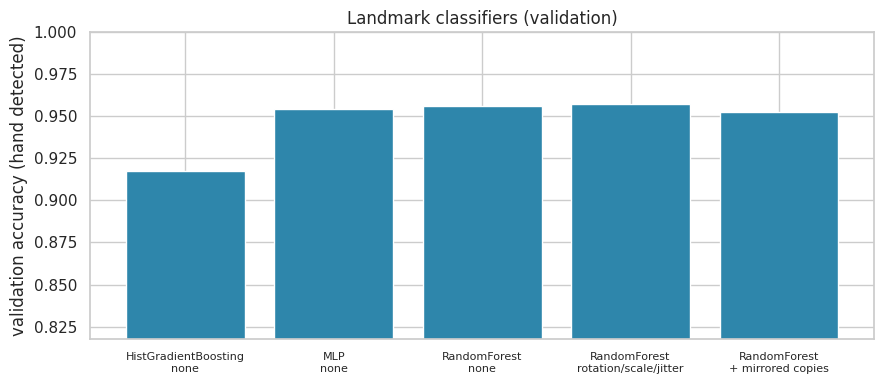

In [7]:
for aug_name, kw in [('rotation/scale/jitter', dict(mirror=False)), ('+ mirrored copies', dict(mirror=True))]:
    t0 = time.time(); Va, ya = augment_lm(LM[dtr], y_all[dtr], rng, copies=3, **kw)
    clf = make_lm(BEST_LM).fit(lm_features(Va), ya); p = clf.predict(lm_features(LM[dva])); LMMODELS[(BEST_LM, aug_name)] = clf
    rows.append({'model': BEST_LM, 'augmentation': aug_name, 'val_acc_detected': accuracy_score(y_all[dva], p), 'val_f1': f1_score(y_all[dva], p, average='macro'), 'secs': round(time.time() - t0)}); print(rows[-1])
lm_tab = pd.DataFrame(rows); display(lm_tab.round(4))
best_row = lm_tab.sort_values('val_f1', ascending=False).iloc[0]; print('Chosen landmark classifier:', best_row['model'], '| augmentation:', best_row['augmentation'])
LM_CLF = LMMODELS[best_row['model']] if best_row['augmentation'] == 'none' else LMMODELS[(best_row['model'], best_row['augmentation'])]
fig, ax = plt.subplots(figsize=(9, 4)); lab = lm_tab['model'] + '\n' + lm_tab['augmentation']
ax.bar(lab, lm_tab['val_acc_detected'], color='#2E86AB'); ax.set_ylim(max(0, lm_tab['val_acc_detected'].min() - .1), 1); ax.set_ylabel('validation accuracy (hand detected)'); ax.set_title('Landmark classifiers (validation)'); plt.xticks(fontsize=8)
plt.tight_layout(); plt.savefig(f'{OUT}/p2_22_landmark_models.png', dpi=130, bbox_inches='tight'); plt.show()

def lm_proba(clf, mask):                                                 # Probabilities for all images in `mask`; NaN where no hand was found
    P = np.full((mask.sum(), K), np.nan, np.float32); det = DET[mask]
    P[det] = clf.predict_proba(lm_features(LM[mask][det])); return P

**What it tells us:** the landmark models see only the hand shape. If their validation accuracy is close to the CNN's (93%), the two are strong, independent views of the same sign, which is what fusion needs.

## 2. Improved CNN training recipe (MobileNetV2, v2)
Two variants are trained and compared with the v1 result (validation accuracy 93.2%, macro-F1 0.931):
- **v2a:** stronger augmentation + label smoothing 0.1 + dropout 0.4, same fine-tuning as v1 (80 layers, lr 1e-4).
- **v2b:** v2a + **all backbone layers** fine-tuned (BatchNorm frozen) with AdamW (weight decay 1e-4) and a cosine learning-rate schedule from 3e-4.

In [8]:
def processed_ok(): return os.path.isdir(PROC) and all(os.path.exists(os.path.join(PROC, p)) for p in imgs['processed_path'])
if not processed_ok():
    zp = f'{DRIVE_DIR}/processed_images.zip'; shutil.copy(zp, '/content/processed_images.zip')
    with zipfile.ZipFile('/content/processed_images.zip') as z: z.extractall(PROC)
assert processed_ok()
def load_array(idx):
    X = np.empty((len(idx), 224, 224, 3), np.uint8); paths = [os.path.join(PROC, imgs.loc[i, 'processed_path']) for i in idx]
    def f(j): X[j] = cv2.cvtColor(cv2.imread(paths[j]), cv2.COLOR_BGR2RGB)
    with ThreadPoolExecutor(max_workers=8) as ex: list(tqdm(ex.map(f, range(len(idx))), total=len(idx)))
    return X
X_tr, X_va = load_array(np.where(tr_m)[0]), load_array(np.where(va_m)[0]); y_tr, y_va = y_all[tr_m], y_all[va_m]; va_orig = orig_m[va_m]
print(X_tr.shape, X_va.shape)

  0%|          | 0/15062 [00:00<?, ?it/s]

  0%|          | 0/3060 [00:00<?, ?it/s]

(15062, 224, 224, 3) (3060, 224, 224, 3)


In [13]:
class ArrayDS(keras.utils.PyDataset):
    def __init__(self, X, y, batch=64, shuffle=False, weights=None, seed=SEED):
        super().__init__(workers=1, use_multiprocessing=False, max_queue_size=4)
        self.X, self.y, self.batch, self.shuffle, self.weights = X, y, batch, shuffle, weights
        self.idx = np.arange(len(X)); self.rng = np.random.default_rng(seed)
        if shuffle: self.rng.shuffle(self.idx)
    def __len__(self): return int(np.ceil(len(self.X) / self.batch))
    def __getitem__(self, i):
        j = self.idx[i * self.batch:(i + 1) * self.batch]; x, y = self.X[j].astype('float32'), np.eye(K, dtype='float32')[self.y[j]]
        return (x, y, np.array([self.weights[c] for c in self.y[j]], 'float32')) if self.weights is not None else (x, y)
    def on_epoch_end(self):
        if self.shuffle: self.rng.shuffle(self.idx)

class SimpleRandomBlur(layers.Layer):
    """Fallback blur (3x3 Gaussian-like kernel, applied to a random share of the batch) in plain TensorFlow ops."""
    def __init__(self, p=0.3, **kw):
        super().__init__(dtype='float32', **kw); self.p = p
    def call(self, x, training=None):
        if not training: return x
        x = tf.cast(x, tf.float32); k1 = tf.constant([1., 2., 1.]) / 4.; k = tf.tile(tf.tensordot(k1, k1, 0)[:, :, None, None], [1, 1, 3, 1])
        blurred = tf.nn.depthwise_conv2d(x, k, [1, 1, 1, 1], 'SAME')
        m = tf.cast(tf.random.uniform([tf.shape(x)[0], 1, 1, 1]) < self.p, tf.float32)
        return m * blurred + (1. - m) * x
    def compute_output_shape(self, s): return s

def layer_works(layer):
    """Run the layer exactly like training does (graph mode, unknown batch size, training=True) so a broken layer is found now, not in epoch 1."""
    try:
        f = tf.function(lambda x: layer(x, training=True), input_signature=[tf.TensorSpec([None, 224, 224, 3], tf.float32)])
        out = f(tf.random.uniform([2, 224, 224, 3], 0., 255.)).numpy()
        return bool(np.isfinite(out).all()), ''
    except Exception as e:
        return False, f'{type(e).__name__}: {str(e)[:160]}'

def make_aug_v2():
    L = layers
    specs = [('RandomRotation', dict(factor=0.06, fill_mode='nearest')), ('RandomTranslation', dict(height_factor=0.10, width_factor=0.10, fill_mode='nearest')),
             ('RandomZoom', dict(height_factor=(-0.25, 0.15), fill_mode='nearest')), ('RandomContrast', dict(factor=0.25)),
             ('RandomBrightness', dict(factor=0.25, value_range=(0, 255))),
             ('RandomColorJitter', dict(value_range=(0, 255), brightness_factor=0.15, contrast_factor=0.15, saturation_factor=0.2, hue_factor=0.03, dtype='float32')),
             ('RandomGaussianBlur', dict(factor=1.0, sigma=1.0, dtype='float32')),
             ('RandomErasing', dict(factor=0.4, scale=(0.02, 0.15), value_range=(0, 255), dtype='float32'))]
    aug = []
    for nm, kw in specs:
        layer, why = None, ''
        try: layer = getattr(L, nm)(**kw); ok, why = layer_works(layer)
        except Exception as e: ok, why = False, f'{type(e).__name__}: {str(e)[:160]}'
        if ok: aug.append(layer); print('augmentation added:', nm)
        elif nm == 'RandomGaussianBlur':
            fb = SimpleRandomBlur(); ok2, why2 = layer_works(fb)
            if ok2: aug.append(fb); print('augmentation added: SimpleRandomBlur (built-in RandomGaussianBlur failed:', why, ')')
            else: print('augmentation skipped:', nm, '->', why)
        else: print('augmentation skipped:', nm, '->', why)
    return keras.Sequential(aug, name='augment_v2')

def build_v2(dropout=0.4):
    inp = keras.Input((224, 224, 3)); x = make_aug_v2()(inp); x = layers.Rescaling(1 / 127.5, offset=-1)(x)
    base = keras.applications.MobileNetV2(include_top=False, weights='imagenet', input_shape=(224, 224, 3), pooling='avg')
    x = base(x, training=False); x = layers.Dropout(dropout)(x); out = layers.Dense(K, activation='softmax', dtype='float32')(x)
    return keras.Model(inp, out, name='mobilenetv2_v2'), base

def set_trainable(base, n_last):
    base.trainable = n_last > 0
    for l in base.layers: l.trainable = False
    if n_last > 0:
        for l in base.layers[-n_last:]:
            if not isinstance(l, layers.BatchNormalization): l.trainable = True

def fit(model, opt, epochs, patience, plateau, ds, val, verbose=2):
    model.compile(optimizer=opt, loss=keras.losses.CategoricalCrossentropy(label_smoothing=0.1), metrics=['accuracy'])
    cbs = [keras.callbacks.EarlyStopping(monitor='val_loss', patience=patience, restore_best_weights=True)]
    if plateau: cbs.append(keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6))
    return model.fit(ds, validation_data=val, epochs=epochs, callbacks=cbs, verbose=verbose).history

def predict(model, X): return np.concatenate([model.predict(X[i:i + 128].astype('float32'), verbose=0) for i in range(0, len(X), 128)])
def val_metrics(P, mask=None):
    p = P.argmax(1); yv = y_va
    if mask is not None: p, yv = p[mask], yv[mask]
    return {'acc': accuracy_score(yv, p), 'f1': f1_score(yv, p, average='macro')}

train_ds, val_ds = ArrayDS(X_tr, y_tr, shuffle=True, weights=CW), ArrayDS(X_va, y_va)
STEPS = len(train_ds); HISTV2, V2 = {}, {}

In [14]:
t0 = time.time(); model, base = build_v2()
set_trainable(base, 0); h1 = fit(model, keras.optimizers.Adam(1e-3), 3, 3, True, train_ds, val_ds); w_head = model.get_weights()
# ---- v2a: stronger augmentation + label smoothing, v1 fine-tuning schedule ----
set_trainable(base, 80); h2 = fit(model, keras.optimizers.Adam(1e-4), 12, 4, True, train_ds, val_ds)
P_va_v2a = predict(model, X_va); V2['v2a'] = {**val_metrics(P_va_v2a), **{k + '_orig': v for k, v in val_metrics(P_va_v2a, va_orig).items()}, 'epochs': len(h1['loss']) + len(h2['loss'])}
HISTV2['v2a'] = {k: h1[k] + h2[k] for k in h1}; model.save(f'{MODELS}/mobilenetv2_v2a.keras'); print('v2a', {k: round(v, 4) for k, v in V2['v2a'].items()}, f'({(time.time() - t0) / 60:.1f} min)')

augmentation added: RandomRotation
augmentation added: RandomTranslation
augmentation added: RandomZoom


augmentation added: RandomContrast
augmentation added: RandomBrightness


augmentation added: RandomColorJitter
augmentation added: RandomGaussianBlur
augmentation added: RandomErasing
Epoch 1/3
236/236 - 55s - 232ms/step - accuracy: 0.3235 - loss: 2.6620 - val_accuracy: 0.5183 - val_loss: 2.0491 - learning_rate: 0.0010
Epoch 2/3
236/236 - 38s - 159ms/step - accuracy: 0.5627 - loss: 1.9203 - val_accuracy: 0.5869 - val_loss: 1.8543 - learning_rate: 0.0010
Epoch 3/3
236/236 - 37s - 157ms/step - accuracy: 0.6266 - loss: 1.7625 - val_accuracy: 0.6144 - val_loss: 1.7988 - learning_rate: 0.0010
Epoch 1/12
236/236 - 70s - 298ms/step - accuracy: 0.8091 - loss: 1.2992 - val_accuracy: 0.8748 - val_loss: 1.1507 - learning_rate: 1.0000e-04
Epoch 2/12
236/236 - 43s - 182ms/step - accuracy: 0.9099 - loss: 1.0237 - val_accuracy: 0.8719 - val_loss: 1.0572 - learning_rate: 1.0000e-04
Epoch 3/12
236/236 - 43s - 184ms/step - accuracy: 0.9384 - loss: 0.9305 - val_accuracy: 0.9026 - val_loss: 0.9797 - learning_rate: 1.0000e-04
Epoch 4/12
236/236 - 43s - 182ms/step - accuracy: 0.

In [16]:
# ---- v2b: v2a + all backbone layers, AdamW + cosine schedule ----
t0 = time.time(); model.set_weights(w_head); set_trainable(base, len(base.layers))
sched = keras.optimizers.schedules.CosineDecay(3e-4, decay_steps=14 * STEPS, alpha=0.02)
h2b = fit(model, keras.optimizers.AdamW(learning_rate=sched, weight_decay=1e-4), 14, 5, False, train_ds, val_ds)
P_va_v2b = predict(model, X_va); V2['v2b'] = {**val_metrics(P_va_v2b), **{k + '_orig': v for k, v in val_metrics(P_va_v2b, va_orig).items()}, 'epochs': len(h1['loss']) + len(h2b['loss'])}
HISTV2['v2b'] = {k: h1[k] + h2b[k] for k in h1 if k in h2b}; model.save(f'{MODELS}/mobilenetv2_v2b.keras'); print('v2b', {k: round(v, 4) for k, v in V2['v2b'].items()}, f'({(time.time() - t0) / 60:.1f} min)')
BEST_V2 = max(V2, key=lambda k: V2[k]['f1']); P_va_v2 = {'v2a': P_va_v2a, 'v2b': P_va_v2b}[BEST_V2]; print('Chosen v2 recipe (best validation macro-F1):', BEST_V2)
del model, base; keras.backend.clear_session()

Epoch 1/14
236/236 - 81s - 345ms/step - accuracy: 0.5394 - loss: 2.0556 - val_accuracy: 0.8902 - val_loss: 0.9848
Epoch 2/14
236/236 - 60s - 253ms/step - accuracy: 0.8995 - loss: 1.0067 - val_accuracy: 0.9222 - val_loss: 0.9264
Epoch 3/14
236/236 - 60s - 252ms/step - accuracy: 0.9422 - loss: 0.8777 - val_accuracy: 0.9105 - val_loss: 0.8905
Epoch 4/14
236/236 - 59s - 251ms/step - accuracy: 0.9554 - loss: 0.8360 - val_accuracy: 0.9105 - val_loss: 0.9210
Epoch 5/14
236/236 - 60s - 253ms/step - accuracy: 0.9646 - loss: 0.8048 - val_accuracy: 0.9395 - val_loss: 0.8252
Epoch 6/14
236/236 - 60s - 253ms/step - accuracy: 0.9693 - loss: 0.7853 - val_accuracy: 0.9225 - val_loss: 0.8598
Epoch 7/14
236/236 - 60s - 253ms/step - accuracy: 0.9746 - loss: 0.7722 - val_accuracy: 0.9278 - val_loss: 0.8645
Epoch 8/14
236/236 - 60s - 253ms/step - accuracy: 0.9790 - loss: 0.7527 - val_accuracy: 0.9307 - val_loss: 0.8461
Epoch 9/14
236/236 - 60s - 254ms/step - accuracy: 0.9827 - loss: 0.7407 - val_accuracy: 

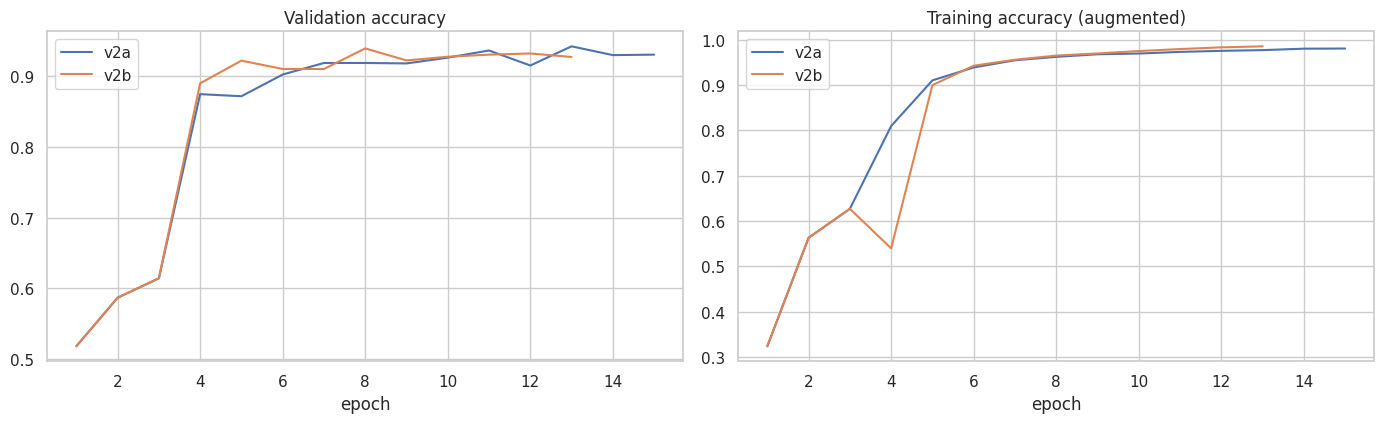

,acc,f1,acc_orig,f1_orig,epochs
v2a,0.9307,0.9297,0.9453,0.9435,15.0
v2b,0.9395,0.9396,0.9476,0.9467,13.0


In [17]:
# Training curves and comparison with v1 (validation accuracy of v1 MobileNetV2 = 0.9324, macro-F1 0.9310)
v1_hist = json.load(open(f'{DRIVE_DIR}/results/static_histories.json'))['MobileNetV2'] if os.path.exists(f'{DRIVE_DIR}/results/static_histories.json') else None
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
for name, h in HISTV2.items(): axes[0].plot(range(1, len(h['val_accuracy']) + 1), h['val_accuracy'], label=name); axes[1].plot(range(1, len(h['accuracy']) + 1), h['accuracy'], label=name)
if v1_hist: axes[0].plot(range(1, len(v1_hist['val_accuracy']) + 1), v1_hist['val_accuracy'], '--', color='gray', label='v1 (previous)'); axes[1].plot(range(1, len(v1_hist['accuracy']) + 1), v1_hist['accuracy'], '--', color='gray', label='v1 (previous)')
axes[0].set_title('Validation accuracy'); axes[1].set_title('Training accuracy (augmented)')
for ax in axes: ax.set_xlabel('epoch'); ax.legend()
plt.tight_layout(); plt.savefig(f'{OUT}/p2_23_cnn_recipe_v2.png', dpi=130, bbox_inches='tight'); plt.show()
display(pd.DataFrame(V2).T.round(4))

**What it tells us:** the gap between the training curve and the validation curve is the overfitting we are fighting. A smaller gap together with a higher validation curve means the new recipe generalises to new people better; the table gives the exact validation numbers to compare with v1 (0.932).

## 3. Fusion (weights chosen on validation)
Components: the **v1 CNN ensemble** (three saved models), the **v2 CNN**, and the **landmark classifier**. For images without a detected hand the fusion uses the CNN components only. For each combination of components the weights are searched on a grid (step 0.1) on the validation split.

In [18]:
# v1 validation predictions (they were not saved earlier)
def load_fp(name):
    m = keras.models.load_model(f'{DRIVE_DIR}/models/{name}.keras', compile=False); P = predict(m, X_va); del m; keras.backend.clear_session(); return P
PV1 = {n: load_fp(f) for n, f in [('Baseline CNN', 'baseline_cnn'), ('MobileNetV2', 'mobilenetv2'), ('EfficientNet-B0', 'efficientnetb0')]}
P_va = {'cnn1_ens': np.mean(list(PV1.values()), axis=0), 'cnn1_mob': PV1['MobileNetV2'], 'cnn2': P_va_v2, 'lm': lm_proba(LM_CLF, va_m)}
for k, v in P_va.items(): print(f'{k:9s} val acc {np.nanmean((np.nan_to_num(v).argmax(1) == y_va)):.4f}' + ('  (images with a hand only: %.4f)' % (v[DET[va_m]].argmax(1) == y_va[DET[va_m]]).mean() if k == 'lm' else ''))

def fuse(Ps, ws):
    num, den = 0, 0
    for P, w in zip(Ps, ws):
        ok = (~np.isnan(P).any(1))[:, None]; num = num + w * np.nan_to_num(P); den = den + w * ok
    return num / np.maximum(den, 1e-9)
def simplex(n, step=0.1):
    grid = np.round(np.arange(0, 1 + 1e-9, step), 2)
    return [w for w in __import__('itertools').product(grid, repeat=n) if abs(sum(w) - 1) < 1e-6]
def search(names, P):
    res = []
    for w in simplex(len(names)):
        f = fuse([P[n] for n in names], w).argmax(1); res.append({'weights': dict(zip(names, w)), 'acc': accuracy_score(y_va, f), 'f1': f1_score(y_va, f, average='macro')})
    return sorted(res, key=lambda r: -r['f1'])

cnn1_ens  val acc 0.9507
cnn1_mob  val acc 0.9324
cnn2      val acc 0.9395
lm        val acc 0.8974  (images with a hand only: 0.9561)


v1 ensemble + landmark             weights {'cnn1_ens': np.float64(0.2), 'lm': np.float64(0.8)}  val acc 0.9585  F1 0.9578
v2 CNN + landmark                  weights {'cnn2': np.float64(0.2), 'lm': np.float64(0.8)}  val acc 0.9585  F1 0.9576
v1 ensemble + v2 CNN               weights {'cnn1_ens': np.float64(0.6), 'cnn2': np.float64(0.4)}  val acc 0.9556  F1 0.9563
v1 ensemble + v2 CNN + landmark    weights {'cnn1_ens': np.float64(0.1), 'cnn2': np.float64(0.2), 'lm': np.float64(0.7)}  val acc 0.9611  F1 0.9602


,candidate,weights,val_acc,val_f1
7,v1 ensemble + v2 CNN + landmark,"{""cnn1_ens"": 0.1, ""cnn2"": 0.2, ""lm"": 0.7}",0.9611,0.9602
4,v1 ensemble + landmark,"{""cnn1_ens"": 0.2, ""lm"": 0.8}",0.9585,0.9578
5,v2 CNN + landmark,"{""cnn2"": 0.2, ""lm"": 0.8}",0.9585,0.9576
6,v1 ensemble + v2 CNN,"{""cnn1_ens"": 0.6, ""cnn2"": 0.4}",0.9556,0.9563
0,v1 CNN ensemble (current app),"{""cnn1_ens"": 1.0}",0.9507,0.9508
2,v2 CNN alone,"{""cnn2"": 1.0}",0.9395,0.9396
1,v1 MobileNetV2 alone,"{""cnn1_mob"": 1.0}",0.9324,0.9310
3,landmark alone,"{""lm"": 1.0}",0.8974,0.9029


SELECTED by validation macro-F1: v1 ensemble + v2 CNN + landmark


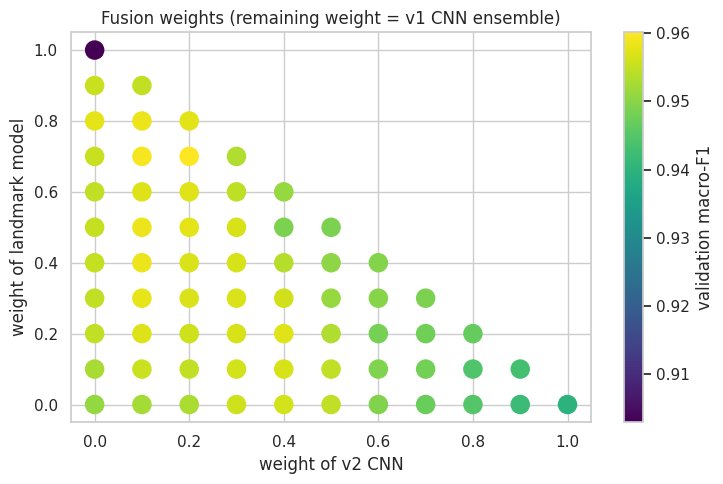

In [19]:
CANDS = {'v1 CNN ensemble (current app)': (['cnn1_ens'], {'cnn1_ens': 1.0}), 'v1 MobileNetV2 alone': (['cnn1_mob'], {'cnn1_mob': 1.0}), 'v2 CNN alone': (['cnn2'], {'cnn2': 1.0}), 'landmark alone': (['lm'], {'lm': 1.0})}
for label, names in [('v1 ensemble + landmark', ['cnn1_ens', 'lm']), ('v2 CNN + landmark', ['cnn2', 'lm']), ('v1 ensemble + v2 CNN', ['cnn1_ens', 'cnn2']), ('v1 ensemble + v2 CNN + landmark', ['cnn1_ens', 'cnn2', 'lm'])]:
    r = search(names, P_va)[0]; CANDS[label] = (names, r['weights']); print(f'{label:34s} weights {r["weights"]}  val acc {r["acc"]:.4f}  F1 {r["f1"]:.4f}')
VAL_TAB = pd.DataFrame([{'candidate': k, 'weights': json.dumps(w), **{m: v for m, v in zip(['val_acc', 'val_f1'], [accuracy_score(y_va, fuse([P_va[n] for n in names], [w[n] for n in names]).argmax(1)),
            f1_score(y_va, fuse([P_va[n] for n in names], [w[n] for n in names]).argmax(1), average='macro')])}} for k, (names, w) in CANDS.items()]).sort_values('val_f1', ascending=False)
display(VAL_TAB.round(4)); SELECTED = VAL_TAB.iloc[0]['candidate']; print('SELECTED by validation macro-F1:', SELECTED)

names3, ws = ['cnn1_ens', 'cnn2', 'lm'], None
grid = pd.DataFrame([{**r['weights'], 'f1': r['f1']} for r in search(names3, P_va)])
fig, ax = plt.subplots(figsize=(7.5, 5)); sc = ax.scatter(grid['cnn2'], grid['lm'], c=grid['f1'], cmap='viridis', s=170); plt.colorbar(sc, label='validation macro-F1')
ax.set_xlabel('weight of v2 CNN'); ax.set_ylabel('weight of landmark model'); ax.set_title('Fusion weights (remaining weight = v1 CNN ensemble)'); plt.tight_layout()
plt.savefig(f'{OUT}/p2_24_fusion_weights.png', dpi=130, bbox_inches='tight'); plt.show()

**What it tells us:** each candidate has its own weights tuned on validation. A flat landscape in the plot means the result is not sensitive to the exact weights; a clear peak away from the corners means the components really complement each other.

## 4. Test evaluation of the candidates (reported once; the selection above used validation only)

In [20]:
del X_tr; import gc; gc.collect()
X_te = load_array(np.where(te_m)[0]); y_te, te_orig, subj_te = y_all[te_m], orig_m[te_m], subj[te_m]
m2 = keras.models.load_model(f'{MODELS}/mobilenetv2_{BEST_V2}.keras', compile=False); P_te2 = predict(m2, X_te); del m2; keras.backend.clear_session()
P_te = {'cnn1_ens': SP['Ensemble_(3_models)'].astype('float32'), 'cnn1_mob': SP['MobileNetV2'].astype('float32'), 'cnn2': P_te2, 'lm': lm_proba(LM_CLF, te_m)}
FUSED = {k: fuse([P_te[n] for n in names], [w[n] for n in names]) for k, (names, w) in CANDS.items()}

def metrics(P, mask=None):
    p, y = P.argmax(1), y_te
    if mask is not None: p, y = p[mask], y[mask]; P = P[mask]
    pr, rc, f1, _ = precision_recall_fscore_support(y, p, average='macro', zero_division=0)
    return {'accuracy': accuracy_score(y, p), 'precision': pr, 'recall': rc, 'f1_macro': f1, 'top3': float((np.argsort(P, 1)[:, -3:] == y[:, None]).any(1).mean())}
rows = []
for k, P in FUSED.items():
    rows.append({'candidate': k, 'subset': 'all', **metrics(P)}); rows.append({'candidate': k, 'subset': 'originals only', **metrics(P, te_orig)})
TEST = pd.DataFrame(rows); display(TEST[TEST.subset == 'all'].drop(columns='subset').round(4).reset_index(drop=True)); display(TEST[TEST.subset == 'originals only'].drop(columns='subset').round(4).reset_index(drop=True))
print('Landmark coverage on test (hand detected):', round(DET[te_m].mean(), 4))

  0%|          | 0/3238 [00:00<?, ?it/s]

,candidate,accuracy,precision,recall,f1_macro,top3
0,v1 CNN ensemble (current app),0.8984,0.9143,0.8977,0.8974,0.9771
1,v1 MobileNetV2 alone,0.8740,0.8951,0.8728,0.8690,0.9725
2,v2 CNN alone,0.8845,0.9025,0.8814,0.8808,0.9793
3,landmark alone,0.8666,0.9060,0.8675,0.8732,0.9376
4,v1 ensemble + landmark,0.9290,0.9341,0.9280,0.9277,0.9892
5,v2 CNN + landmark,0.9243,0.9314,0.9234,0.9222,0.9889
6,v1 ensemble + v2 CNN,0.9129,0.9239,0.9119,0.9110,0.9778
7,v1 ensemble + v2 CNN + landmark,0.9311,0.9381,0.9309,0.9294,0.9895


,candidate,accuracy,precision,recall,f1_macro,top3
0,v1 CNN ensemble (current app),0.9302,0.9348,0.9303,0.9285,0.9907
1,v1 MobileNetV2 alone,0.9070,0.9186,0.9072,0.9042,0.9884
2,v2 CNN alone,0.9186,0.9293,0.9188,0.9190,0.9884
3,landmark alone,0.8744,0.9146,0.8746,0.8848,0.9349
4,v1 ensemble + landmark,0.9372,0.9397,0.9375,0.9375,0.9977
5,v2 CNN + landmark,0.9372,0.9389,0.9375,0.9376,0.9977
6,v1 ensemble + v2 CNN,0.9372,0.9423,0.9375,0.9369,0.9953
7,v1 ensemble + v2 CNN + landmark,0.9442,0.9472,0.9444,0.9444,0.9977


Landmark coverage on test (hand detected): 0.9435


,candidate,subset,accuracy,ci_low,ci_high
0,v1 CNN ensemble (current app),all,0.8984,0.8628,0.9463
1,v1 CNN ensemble (current app),originals only,0.9302,0.9070,0.9512
2,v1 MobileNetV2 alone,all,0.8740,0.8385,0.9165
3,v1 MobileNetV2 alone,originals only,0.9070,0.8721,0.9375
4,v2 CNN alone,all,0.8845,0.8170,0.9599
5,v2 CNN alone,originals only,0.9186,0.8727,0.9556
6,landmark alone,all,0.8666,0.8217,0.9012
7,landmark alone,originals only,0.8744,0.7986,0.9259
8,v1 ensemble + landmark,all,0.9290,0.9011,0.9505
9,v1 ensemble + landmark,originals only,0.9372,0.9144,0.9578


,candidate,subset,gain_vs_v1_ensemble,ci_low,ci_high,real_improvement
0,v1 MobileNetV2 alone,all,-0.0245,-0.0356,-0.0080,False
1,v1 MobileNetV2 alone,originals only,-0.0231,-0.0486,-0.0023,False
2,v2 CNN alone,all,-0.0119,-0.0545,0.0314,False
3,v2 CNN alone,originals only,-0.0114,-0.0395,0.0163,False
4,landmark alone,all,-0.0341,-0.1226,0.0267,False
5,landmark alone,originals only,-0.0554,-0.1273,-0.0046,False
6,v1 ensemble + landmark,all,0.0288,0.0025,0.0665,True
7,v1 ensemble + landmark,originals only,0.0073,-0.0208,0.0349,False
8,v2 CNN + landmark,all,0.0242,-0.0145,0.0728,False
9,v2 CNN + landmark,originals only,0.0072,-0.0140,0.0324,False


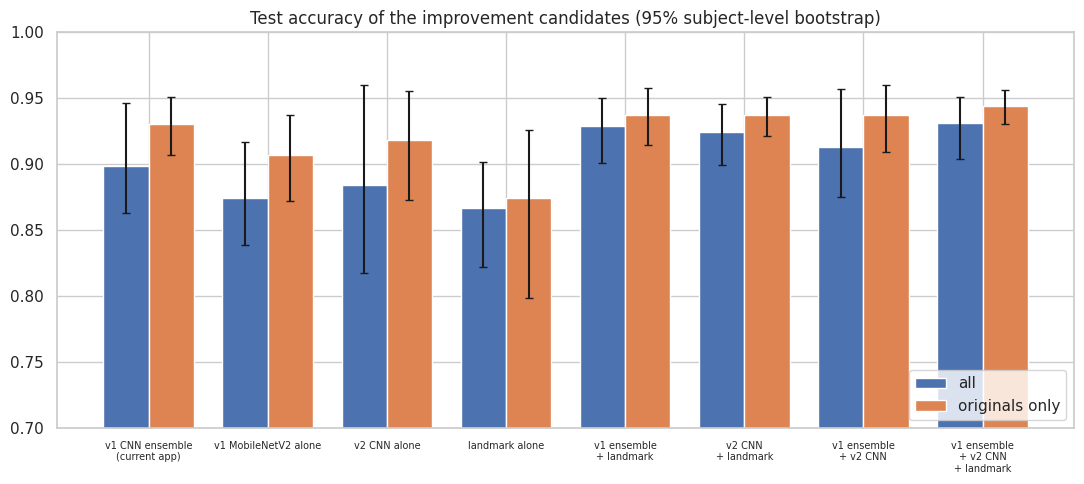

In [21]:
def cluster_boot(Pd, mask=None, B=2000, seed=0):
    keep = np.ones(len(y_te), bool) if mask is None else mask
    s, yy = subj_te[keep], y_te[keep]; subs, inv = np.unique(s, return_inverse=True); S = len(subs); n = np.bincount(inv, minlength=S).astype(float)
    cs = {m: np.bincount(inv, weights=(P[keep].argmax(1) == yy).astype(float), minlength=S) for m, P in Pd.items()}
    idx = np.random.default_rng(seed).integers(0, S, (B, S)); return {m: cs[m][idx].sum(1) / n[idx].sum(1) for m in cs}
ci = lambda a: np.percentile(a, [2.5, 97.5])
bo_all, bo_orig = cluster_boot(FUSED), cluster_boot(FUSED, te_orig)
CIT = pd.DataFrame([{'candidate': k, 'subset': lab, 'accuracy': metrics(FUSED[k], om)['accuracy'], 'ci_low': ci(b[k])[0], 'ci_high': ci(b[k])[1]}
                    for k in FUSED for lab, b, om in [('all', bo_all, None), ('originals only', bo_orig, te_orig)]]); display(CIT.round(4))
BASE = 'v1 CNN ensemble (current app)'; DIFF = []
for k in FUSED:
    if k == BASE: continue
    for lab, b in [('all', bo_all), ('originals only', bo_orig)]:
        d = b[k] - b[BASE]; lo, hi = ci(d); DIFF.append({'candidate': k, 'subset': lab, 'gain_vs_v1_ensemble': d.mean(), 'ci_low': lo, 'ci_high': hi, 'real_improvement': bool(lo > 0)})
DIFF = pd.DataFrame(DIFF); display(DIFF.round(4))

fig, ax = plt.subplots(figsize=(11, 5)); order = list(FUSED); xs = np.arange(len(order)); w = .38
for k, lab in enumerate(['all', 'originals only']):
    d = CIT[CIT.subset == lab].set_index('candidate').loc[order]; ax.bar(xs + (k - .5) * w, d['accuracy'], w, yerr=[d['accuracy'] - d['ci_low'], d['ci_high'] - d['accuracy']], capsize=3, label=lab)
ax.set_xticks(xs); ax.set_xticklabels([o.replace(' + ', '\n+ ').replace(' (current app)', '\n(current app)') for o in order], fontsize=7); ax.set_ylim(.7, 1); ax.legend(loc='lower right')
ax.set_title('Test accuracy of the improvement candidates (95% subject-level bootstrap)'); plt.tight_layout(); plt.savefig(f'{OUT}/p2_25_improvement_test.png', dpi=130, bbox_inches='tight'); plt.show()

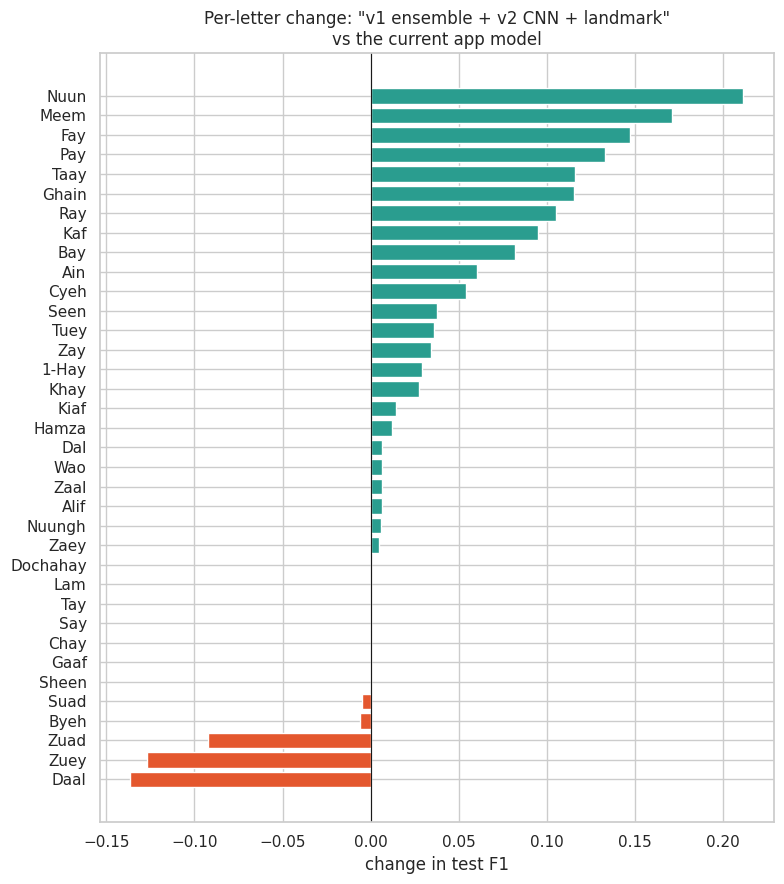

Hard letters from before (Zay, Taay, Tay, Nuungh, Kiaf, Fay) -> change in F1:
Zay       0.034
Taay      0.116
Tay       0.000
Nuungh    0.006
Kiaf      0.014
Fay       0.147
Selected candidate: test accuracy 0.9311 | top-3 0.9895


In [22]:
# Per-class gain of the SELECTED candidate over the current app model
def f1c(P): return precision_recall_fscore_support(y_te, P.argmax(1), labels=range(K), zero_division=0)[2]
gain = pd.Series(f1c(FUSED[SELECTED]) - f1c(FUSED[BASE]), index=STATIC).sort_values()
fig, ax = plt.subplots(figsize=(8, 9)); ax.barh(gain.index, gain.values, color=np.where(gain.values >= 0, '#2A9D8F', '#E4572E')); ax.axvline(0, color='k', lw=.8)
ax.set_xlabel('change in test F1'); ax.set_title(f'Per-letter change: "{SELECTED}"\nvs the current app model'); plt.tight_layout(); plt.savefig(f'{OUT}/p2_26_per_class_gain.png', dpi=130, bbox_inches='tight'); plt.show()
print('Hard letters from before (Zay, Taay, Tay, Nuungh, Kiaf, Fay) -> change in F1:'); print(gain[['Zay', 'Taay', 'Tay', 'Nuungh', 'Kiaf', 'Fay']].round(3).to_string())
print('Selected candidate: test accuracy', round(metrics(FUSED[SELECTED])['accuracy'], 4), '| top-3', round(metrics(FUSED[SELECTED])['top3'], 4))

## 5. Save

In [23]:
names, w = CANDS[SELECTED]
cfg = {'selected': SELECTED, 'components': {n: float(w[n]) for n in names}, 'cnn_v2_file': f'mobilenetv2_{BEST_V2}.keras', 'v1_ensemble_files': ['baseline_cnn_fp32.keras', 'mobilenetv2_fp32.keras', 'efficientnetb0_fp32.keras'],
       'landmark_model': {'family': best_row['model'], 'augmentation': best_row['augmentation'], 'file': 'static_landmark_clf.joblib', 'features': '63 normalized coordinates + 210 pairwise distances'}}
json.dump(cfg, open(f'{OUT}/static_improvement_config.json', 'w'), indent=1); joblib.dump(LM_CLF, f'{MODELS}/static_landmark_clf.joblib', compress=3)
print('Landmark model file size (MB):', round(os.path.getsize(f'{MODELS}/static_landmark_clf.joblib') / 1e6, 1), '(if above 50 MB do not commit it; the app can retrain it from a small data file)')
TEST.to_csv(f'{OUT}/static_improvement_test.csv', index=False); VAL_TAB.to_csv(f'{OUT}/static_improvement_val.csv', index=False); CIT.to_csv(f'{OUT}/static_improvement_ci.csv', index=False); DIFF.to_csv(f'{OUT}/static_improvement_diffs.csv', index=False)
lm_tab.to_csv(f'{OUT}/static_landmark_models_val.csv', index=False); pd.DataFrame(V2).T.to_csv(f'{OUT}/static_cnn_v2_val.csv'); gain.to_csv(f'{OUT}/static_improvement_per_class_gain.csv')
np.savez_compressed(f'{OUT}/static_improvement_test_predictions.npz', **{k.replace(' ', '_'): v.astype('float16') for k, v in FUSED.items()}, y=y_te)
for f in os.listdir(MODELS): shutil.copy(f'{MODELS}/{f}', f'{DRIVE_DIR}/models/{f}')
for f in os.listdir(OUT):
    if os.path.isfile(f'{OUT}/{f}'): shutil.copy(f'{OUT}/{f}', f'{DRIVE_DIR}/results/{f}')
print(sorted(os.listdir(OUT)), sorted(os.listdir(MODELS)))

Landmark model file size (MB): 5.2 (if above 50 MB do not commit it; the app can retrain it from a small data file)
['models', 'p2_22_landmark_models.png', 'p2_23_cnn_recipe_v2.png', 'p2_24_fusion_weights.png', 'p2_25_improvement_test.png', 'p2_26_per_class_gain.png', 'static_cnn_v2_val.csv', 'static_improvement_ci.csv', 'static_improvement_config.json', 'static_improvement_diffs.csv', 'static_improvement_per_class_gain.csv', 'static_improvement_test.csv', 'static_improvement_test_predictions.npz', 'static_improvement_val.csv', 'static_landmark_models_val.csv'] ['mobilenetv2_v2a.keras', 'mobilenetv2_v2b.keras', 'static_landmark_clf.joblib']


In [24]:
def hdr(t): print('\n' + '=' * 70 + f'\n{t}\n' + '=' * 70)
hdr('Landmark detection'); print(f'all {DET.mean():.3f} | train {DET[tr_m].mean():.3f} | val {DET[va_m].mean():.3f} | test {DET[te_m].mean():.3f}')
hdr('Landmark classifiers (validation)'); print(lm_tab.round(4).to_string(index=False)); print('chosen:', best_row['model'], '|', best_row['augmentation'])
hdr('CNN v2 recipes (validation)'); print(pd.DataFrame(V2).T.round(4).to_string()); print('chosen:', BEST_V2, '| v1 MobileNetV2 reference: acc 0.9324, F1 0.9310')
hdr('Fusion candidates (validation)'); print(VAL_TAB.round(4).to_string(index=False)); print('SELECTED:', SELECTED)
hdr('TEST, all images'); print(TEST[TEST.subset == 'all'].drop(columns='subset').round(4).to_string(index=False))
hdr('TEST, originals only'); print(TEST[TEST.subset == 'originals only'].drop(columns='subset').round(4).to_string(index=False))
hdr('Bootstrap CI of test accuracy'); print(CIT.round(4).to_string(index=False))
hdr('Paired gain vs the current v1 ensemble'); print(DIFF.round(4).to_string(index=False))
hdr('Hard letters, change in F1'); print(gain[['Zay', 'Taay', 'Tay', 'Nuungh', 'Kiaf', 'Fay']].round(3).to_string())
hdr('Files'); print(sorted(os.listdir(OUT)), sorted(os.listdir(MODELS)))


Landmark detection
all 0.943 | train 0.944 | val 0.939 | test 0.943

Landmark classifiers (validation)
               model          augmentation  val_acc_detected  val_f1  secs
HistGradientBoosting                  none            0.9175  0.9079    73
                 MLP                  none            0.9544  0.9469    11
        RandomForest                  none            0.9561  0.9495    74
        RandomForest rotation/scale/jitter            0.9572  0.9494   393
        RandomForest     + mirrored copies            0.9526  0.9447   690
chosen: RandomForest | none

CNN v2 recipes (validation)
        acc      f1  acc_orig  f1_orig  epochs
v2a  0.9307  0.9297    0.9453   0.9435    15.0
v2b  0.9395  0.9396    0.9476   0.9467    13.0
chosen: v2b | v1 MobileNetV2 reference: acc 0.9324, F1 0.9310

Fusion candidates (validation)
                      candidate                                   weights  val_acc  val_f1
v1 ensemble + v2 CNN + landmark {"cnn1_ens": 0.1, "cnn2": 0.2, 